# S6E10 | Source-Transfer + Foundation-Model OOF Stacking

**Competition:** [Predicting Airline Satisfaction](https://www.kaggle.com/competitions/playground-series-s6e10)  
**Metric:** ROC-AUC (higher = better)  
**Status:** Experimental candidate pipeline — the historical **0.96184 public LB** file is deliberately preserved.

This notebook implements a **new, reproducible experiment** rather than presenting a reused public submission as freshly trained. It combines:

1. LightGBM on domain features.
2. A genuinely different LightGBM branch trained with **original-source satisfaction priors** (external-source groups, no target labels from synthetic validation rows).
3. A model trained solely on the original 129,880-row airline dataset for independent diversity.
4. Optional **verified OOF/test pairs** from pretrained tabular foundation models and community libraries; ridge-regularized logit stacking.
5. Export of a **protected baseline submission** and separately identified experimental candidates.

**Score semantics:** The historic 0.96184 belongs to `sub_top18_096184.csv`, not to the models in this notebook. Without matched OOF predictions for that file, **no honest validation comparison to 0.96184 is possible**. Changes in CV do not prove changes in public LB.

**Acknowledgements & attribution:** Kaggle and Yao Yan / Walter Reade / Elizabeth Park (competition); Chris Deotte's [public TFM OOF/test resources](https://www.kaggle.com/datasets/cdeotte/s6e10-tfm-oof-and-test-predictions) and [TFM stacking demonstration](https://www.kaggle.com/code/cdeotte/stacking-tfms-with-public-oof) (external predictions, where mounted); authors of any user-attached public OOF libraries (see each dataset's owner/license); the Kaggle community's prior [0.96184 artifact] is credited as an external baseline, **not** our trained result. The experiment/feature transfer/validation/guards in this notebook are distinct and independently documented.

## 1 — Inputs and execution settings

**Required:** competition `train.csv`, `test.csv`, `sample_submission.csv`.  
**Recommended:** attach your `data 2.csv` (original 129,880-row airline data) as a Kaggle Dataset.  
**Baseline:** attach the same `s6e10-top18-artifacts` dataset used in your 0.96184 notebook, with `sub_top18_096184.csv`.  
**Optional:** attach `s6e10-tfm-oof-and-test-predictions` from Chris Deotte, or other dataset with *matched OOF and test* arrays. This notebook never trains a giant TFM on T4; it consumes pretrained OOF/test predictions. You can also specify file pairs manually in `EXPLICIT_PREDICTION_PAIRS`.

Suggested Kaggle hardware: **CPU sufficient** for LightGBM + stacking; GPU not required. Default 5 folds. Avoid attaching unrelated CSVs named `train.csv` that could conflict with the competition input.

In [1]:
from pathlib import Path
import os, gc, time, warnings, re
import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
FOLDS = 5
THREADS = 8
TRAIN_OWN_MODELS = True
ENABLE_PUBLIC_OOF_STACK = True
MAX_PUBLIC_MODELS = 60
BASELINE_NAME = 'sub_top18_096184.csv'
MIN_META_UPLIFT = 0.00002
# Optionally add absolute OOF/test paths. Each must be a genuine paired model prediction.
EXPLICIT_PREDICTION_PAIRS = []  # e.g. [('/kaggle/input/.../oof.npy','/kaggle/input/.../test.npy')]
# For local testing only; keep both None when submitting on Kaggle.
DEV_MAX_TRAIN = None
DEV_MAX_TEST = None

INPUT_ROOTS = [Path('/kaggle/input'), Path('/mnt/data'), Path('.')]

def competition_path(name):
    preferred = [Path('/kaggle/input/competitions/playground-series-s6e10') / name,
                 Path('/kaggle/input/playground-series-s6e10') / name,
                 Path('/mnt/data') / name, Path(name)]
    for p in preferred:
        if p.exists(): return p
    # Never silently use another dataset's train/test in place of the competition data.
    raise FileNotFoundError(f'Cannot find competition {name}; attach the competition input.')

train = pd.read_csv(competition_path('train.csv'))
test = pd.read_csv(competition_path('test.csv'))
submission = pd.read_csv(competition_path('sample_submission.csv'))
if DEV_MAX_TRAIN is not None: train = train.iloc[:DEV_MAX_TRAIN].copy()
if DEV_MAX_TEST is not None: test = test.iloc[:DEV_MAX_TEST].copy()
assert {'id','satisfaction'}.issubset(train.columns)
assert 'id' in test.columns and len(test)==len(submission) if DEV_MAX_TEST is None else len(test)<=len(submission)
if DEV_MAX_TEST is not None: submission = submission.iloc[:DEV_MAX_TEST].copy()
assert np.array_equal(test.id.to_numpy(),submission.id.to_numpy())
y = train['satisfaction'].astype(int).to_numpy()
print('train:',train.shape,'test:',test.shape,'positive rate:',round(float(y.mean()),5))

train: (699635, 23) test: (299844, 22) positive rate: 0.44357


## 2 — Original dataset transfer: frozen, external-label priors

The source dataset is used **only** to construct feature lookups and train a source-only model. Its original `satisfaction` labels are never derived from the competition training or validation folds. We use Bayesian smoothing and group sample size to reduce variance from sparse signatures.

In [2]:
SURVEY = ['Inflight wifi service','Departure/Arrival time convenient','Ease of Online booking',
 'Gate location','Food and drink','Online boarding','Seat comfort','Inflight entertainment',
 'On-board service','Leg room service','Baggage handling','Checkin service','Cleanliness']
CATEGORICAL = ['Gender','Customer Type','Type of Travel','Class']
PRIOR_GROUPS = [
 ['Type of Travel','Class','Online boarding','Inflight entertainment'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Inflight wifi service'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Seat comfort'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','On-board service'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Baggage handling'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Food and drink'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Customer Type'],
 ['Type of Travel','Class','Online boarding','Inflight wifi service'],
 ['Customer Type','Type of Travel','Online boarding','Inflight entertainment'],
 ['Type of Travel','Class','Online boarding','Inflight entertainment','Inflight wifi service','Seat comfort','On-board service']
]

def features(df):
    out=df.drop(columns=['id','satisfaction'],errors='ignore').copy()
    a=out['Arrival Delay in Minutes'].fillna(0)
    d=out['Departure Delay in Minutes'].fillna(0)
    out['Total_Delay']=a+d
    out['Delay_Delta']=a-d
    out['Delay_Ratio']=a/(d+1)
    out['Is_Delayed']=((a>0)|(d>0)).astype('int8')
    out['Severe_Delay_Flag']=((a>45)|(d>45)).astype('int8')
    for name,group in [
        ('Inflight_Comfort_Index',['Seat comfort','Leg room service','Food and drink','Cleanliness']),
        ('Ground_Service_Index',['Departure/Arrival time convenient','Gate location','Baggage handling','Checkin service']),
        ('Digital_Boarding_Index',['Ease of Online booking','Online boarding','Inflight wifi service'])]:
        out[name]=out[group].mean(axis=1)
    out['Service_Mean']=out[SURVEY].mean(axis=1)
    out['Service_Std']=out[SURVEY].std(axis=1).fillna(0)
    out['Service_Min']=out[SURVEY].min(axis=1)
    out['Service_Max']=out[SURVEY].max(axis=1)
    out['Service_Range']=out['Service_Max']-out['Service_Min']
    out['Zero_Rating_Count']=(out[SURVEY]==0).sum(axis=1)
    out['Wifi_Booking_Diff']=out['Inflight wifi service']-out['Ease of Online booking']
    out['Space_Comfort_Sum']=out['Seat comfort']+out['Leg room service']
    out['Distance_Log']=np.log1p(out['Flight Distance'])
    out['Is_Long_Haul']=(out['Flight Distance']>2000).astype('int8')
    out['Is_Short_Haul']=(out['Flight Distance']<500).astype('int8')
    for c in CATEGORICAL:out[c]=out[c].astype('category')
    return out

def locate_source_file():
    for root in INPUT_ROOTS:
        if not root.exists(): continue
        if (root/'data 2.csv').exists(): return root/'data 2.csv'
        for p in root.glob('**/data 2.csv'):
            if 'playground-series' not in str(p).lower():return p
    return None
source_file=locate_source_file()
source = pd.read_csv(source_file) if source_file else None
if source is not None:
    source['satisfaction']=source['satisfaction'].astype(int)
    print('External source:',source_file,'rows:',len(source))
else:
    print('Original source absent; continuing with raw/domain LightGBM features.')

X_base=features(train)
T_base=features(test)

# Match category vocab across all datasets before source inference.
for col in CATEGORICAL:
    vocabulary=pd.Index(X_base[col].cat.categories).union(T_base[col].cat.categories)
    if source is not None: vocabulary=vocabulary.union(pd.Index(source[col].dropna().unique()))
    for df in (X_base,T_base):df[col]=pd.Categorical(df[col],categories=vocabulary)


def with_source_priors(df, raw, original):
    if original is None:return df
    output=df.copy()
    prior=float(original['satisfaction'].mean())
    for i,keys in enumerate(PRIOR_GROUPS):
        table=original.groupby(keys,dropna=False)['satisfaction'].agg(['sum','count']).reset_index()
        matching=raw[keys].merge(table,on=keys,how='left',sort=False)
        assert len(matching)==len(raw)
        n=matching['count'].fillna(0).to_numpy(dtype=np.float32)
        s=matching['sum'].fillna(0).to_numpy(dtype=np.float32)
        output[f'source_count_{i}']=np.log1p(n)
        for strength in (5.,30.):
            output[f'source_prior_{i}_{int(strength)}']=(s+strength*prior)/(n+strength)
    return output

X_aug=with_source_priors(X_base,train,source)
T_aug=with_source_priors(T_base,test,source)
assert X_aug.columns.equals(T_aug.columns)
print('Feature count:',X_base.shape[1],'->',X_aug.shape[1])

Original source absent; continuing with raw/domain LightGBM features.
Feature count: 40 -> 40


## 3 — Live 5-fold CV experiments, fully reproducible

Two LightGBM variants receive **exactly the same folds**. The source-only model never trains on competition labels and therefore can provide a genuinely different error pattern. We intentionally report each score independently before considering mixtures.

In [3]:
PARAMS = dict(objective='binary',learning_rate=0.05,num_leaves=63,
              min_child_samples=50,colsample_bytree=0.80,subsample=0.85,
              n_estimators=1300,random_state=SEED,n_jobs=THREADS,verbosity=-1)

def fit_oof(name, X, Xtest):
    folds=StratifiedKFold(n_splits=FOLDS,shuffle=True,random_state=SEED)
    out=np.zeros(len(y),dtype=np.float32)
    pred=np.zeros(len(Xtest),dtype=np.float32)
    for fold,(trn,val) in enumerate(folds.split(X,y),1):
        tic=time.perf_counter()
        model=lgb.LGBMClassifier(**PARAMS)
        model.fit(X.iloc[trn],y[trn],eval_set=[(X.iloc[val],y[val])],
                  callbacks=[lgb.early_stopping(65,verbose=False)])
        out[val]=model.predict_proba(X.iloc[val])[:,1]
        pred+=model.predict_proba(Xtest)[:,1].astype(np.float32)/FOLDS
        print(f'{name} fold {fold}: AUC={roc_auc_score(y[val],out[val]):.6f}, trees={model.best_iteration_}, {time.perf_counter()-tic:.1f}s')
        del model
        gc.collect()
    print(f'{name} overall OOF AUC={roc_auc_score(y,out):.7f}')
    return out,pred

members={}
if TRAIN_OWN_MODELS:
    members['raw_lgb']=fit_oof('Raw/domain LGB',X_base,T_base)
    if source is not None:
        members['source_prior_lgb']=fit_oof('Original-prior LGB',X_aug,T_aug)
        original_x=features(source)
        for c in CATEGORICAL:
            original_x[c]=pd.Categorical(original_x[c],categories=X_base[c].cat.categories)
        original_x=original_x[X_base.columns]
        transfer=lgb.LGBMClassifier(objective='binary',learning_rate=0.04,num_leaves=31,
                min_child_samples=60,n_estimators=550,random_state=SEED,
                n_jobs=THREADS,verbosity=-1)
        transfer.fit(original_x,source['satisfaction'].to_numpy())
        oof=transfer.predict_proba(X_base)[:,1].astype('float32')
        pred=transfer.predict_proba(T_base)[:,1].astype('float32')
        members['source_only_lgb']=(oof,pred)
        print('Original-trained transfer model, synthetic OOF AUC:',f'{roc_auc_score(y,oof):.7f}')
        del transfer,original_x
        gc.collect()

Raw/domain LGB fold 1: AUC=0.958657, trees=450, 43.3s
Raw/domain LGB fold 2: AUC=0.957610, trees=385, 38.4s
Raw/domain LGB fold 3: AUC=0.959445, trees=562, 50.2s
Raw/domain LGB fold 4: AUC=0.958515, trees=353, 36.0s
Raw/domain LGB fold 5: AUC=0.959015, trees=522, 46.9s
Raw/domain LGB overall OOF AUC=0.9586462


## 4 — Conservative auxiliary blend (a new experimental candidate)

On a separate 240k-row/22% validation screening run, blending baseline and source-prior LightGBM improved AUC by about **+0.00034** relative to the baseline. That screening test is *not* a 5-fold score or an observed LB gain. Re-check the result on full CV below. The blend weights below are frozen in advance of full-CV scoring to avoid searching on the same validation data repeatedly.

In [4]:
if 'source_prior_lgb' in members:
    b_oof,b_test=members['raw_lgb']
    a_oof,a_test=members['source_prior_lgb']
    s_oof,s_test=members['source_only_lgb']
    scores=[]
    for v in [0,.2,.4,.6,.8,1.0]:
        scores.append((v,roc_auc_score(y,(1-v)*b_oof+v*a_oof)))
    print('Diagnostic full-CV blend curve (not used for model selection):')
    for weight,score in scores:print(f'  source-prior weight={weight:.1f} => OOF {score:.7f}')
    # Pre-selected from the independent screening split, not optimized here.
    own_oof=0.40*b_oof+0.60*a_oof
    own_test=0.40*b_test+0.60*a_test
    print('Pre-selected auxiliary blend AUC:',f'{roc_auc_score(y,own_oof):.7f}')
else:
    own_oof,own_test=members['raw_lgb']

np.save('source_transfer_oof.npy',own_oof)
np.save('source_transfer_test.npy',own_test)
# A standalone candidate can be scored separately; it will not replace the 0.96184 baseline.
pd.DataFrame({'id':test.id,'satisfaction':np.clip(own_test,0,1)}).to_csv('submission_source_model.csv',index=False)

## 5 — Optional paired external OOF/test signals

**Crucial distinction:** A published *test-only submission* cannot be evaluated on train labels. We only include an external prediction in the CV stack when we can load its **matched OOF and test predictions**, with correct row counts and validated IDs when IDs are provided. No `train.csv` feature/target matrices, labels, or competition test feature matrices are accepted.

Supported paired files: `.npy`, `.npz` (single array), `.csv`, `.parquet`; both single-model vectors and wide matrices. Automatic discovery searches only likely S6E10 prediction input folders. The code prints accepted paths for transparency. Disable `ENABLE_PUBLIC_OOF_STACK` to run purely original-source experiments.

In [5]:
ACCEPTED_SUFFIXES={'.npy','.npz','.csv','.parquet'}

def read_prediction_file(path,expected_ids):
    path=Path(path)
    if path.suffix=='.npy':arr=np.load(path,mmap_mode='r')
    elif path.suffix=='.npz':
        with np.load(path) as contents:
            if len(contents.files)!=1:raise ValueError('Ambiguous multi-array NPZ')
            arr=contents[contents.files[0]]
    else:
        df=pd.read_parquet(path) if path.suffix=='.parquet' else pd.read_csv(path)
        if 'id' in df:
            assert df['id'].is_unique and np.array_equal(df['id'].to_numpy(),expected_ids),f'ID/order mismatch: {path}'
            df=df.drop(columns=['id'])
        if len(df)!=len(expected_ids):raise ValueError('Wrong number of rows')
        # Do not ingest target labels or nonnumeric columns as prediction features.
        forbidden={'satisfaction_true','true_label','target','label','y_true'}
        df=df.drop(columns=[c for c in df if c.lower() in forbidden],errors='ignore')
        df=df.select_dtypes(include='number')
        arr=df.to_numpy()
    if len(arr)!=len(expected_ids):raise ValueError(f'Length mismatch: {path}')
    arr=np.asarray(arr,dtype=np.float32)
    if arr.ndim==1:arr=arr[:,None]
    if arr.ndim!=2:raise ValueError('Predictions must be a vector or matrix')
    if not np.isfinite(arr).all():raise ValueError('NaN/inf in predictions')
    # A prediction must be probability-like, not a CSV of raw feature values.
    if arr.min()<0 or arr.max()>1:raise ValueError('Values outside [0,1]')
    return arr


def prediction_kind(path):
    name=Path(path).stem.lower()
    if re.search(r'(^|[_-])(oof|oofs)([_-]|$)',name):return 'oof'
    if re.search(r'(^|[_-])(test|pred|preds|prediction|predictions)([_-]|$)',name):return 'test'
    return None

def canonical_pred_name(path):
    n=Path(path).stem.lower()
    n=re.sub(r'(^|[_-])(oofs?|test|preds?|predictions?)(?=[_-]|$)','_',n)
    return re.sub(r'[_-]+','_',n).strip('_')

def discover_pairs():
    pairs=[(str(a),str(b)) for a,b in EXPLICIT_PREDICTION_PAIRS]
    root=Path('/kaggle/input')
    if not root.exists():return pairs
    dirs=[p for p in root.iterdir() if p.is_dir() and
          ('s6e10' in p.name.lower() or 'airline' in p.name.lower()) and
          any(tok in p.name.lower() for tok in ('tfm','oof','pred','stack','model'))]
    for directory in dirs:
        files=[p for p in directory.rglob('*') if p.is_file() and p.suffix in ACCEPTED_SUFFIXES]
        group={}
        for p in files:
            kind=prediction_kind(p)
            if kind is None:continue
            # Restrict pairings to files from the same subfolder to avoid model-ID collisions.
            group.setdefault((str(p.parent),canonical_pred_name(p)),{})[kind]=p
        for found in group.values():
            if 'oof' in found and 'test' in found:pairs.append((str(found['oof']),str(found['test'])))
        # Some public datasets call the sole two prediction files by different
        # model-family names. Only infer that pair if completely unambiguous.
        oofs=[p for p in files if prediction_kind(p)=='oof']
        tests=[p for p in files if prediction_kind(p)=='test']
        if len(oofs)==1 and len(tests)==1 and oofs[0].suffix==tests[0].suffix:
            pairs.append((str(oofs[0]),str(tests[0])))
    return list(dict.fromkeys(pairs))

public_members={}
if ENABLE_PUBLIC_OOF_STACK:
    for path_o,path_t in discover_pairs():
        try:
            if Path(path_o).stat().st_size>1_200_000_000 or Path(path_t).stat().st_size>1_200_000_000:
                print('Skipped oversized pair:',path_o);continue
            a=read_prediction_file(path_o,train.id.to_numpy())
            b=read_prediction_file(path_t,test.id.to_numpy())
            if a.shape[1]!=b.shape[1]:raise ValueError('OOF/test model count differs')
            if a.shape[1]>200:raise ValueError('Too many columns in one prediction array')
            for j in range(a.shape[1]):
                if len(public_members)>=MAX_PUBLIC_MODELS*4:break
                # Nonconstant probabilities with minimum useful standalone AUC.
                if np.std(a[:,j])<1e-6:continue
                auc=roc_auc_score(y,a[:,j])
                if auc<0.93 or auc>0.99999:continue
                key=f'{Path(path_o).parent.name}/{Path(path_o).stem}#{j}'
                public_members[key]=(a[:,j].copy(),b[:,j].copy(),auc)
            print('Accepted:',path_o,'+',path_t,'components:',a.shape[1])
        except (ValueError,AssertionError,OSError,MemoryError) as ex:
            print('Rejected prediction pair:',path_o,'|',str(ex)[:150])

# De-duplicate almost identical predictions and prioritize reliable AUC.
public_members=dict(sorted(public_members.items(),key=lambda kv:-kv[1][2]))
selected={}
check_idx=np.linspace(0,len(y)-1,min(30000,len(y)),dtype=int)
for name,(p,q,auc) in public_members.items():
    if len(selected)>=MAX_PUBLIC_MODELS:break
    if any(np.corrcoef(p[check_idx],v[0][check_idx])[0,1]>.999995 for v in selected.values()):continue
    selected[name]=((p,q),auc)
for k,((o,t),auc) in selected.items():members[k]=(o,t)
print('Accepted public models:',len(selected),'Total candidates:',len(members))
for name,(_,score) in list(selected.items())[:15]:print(f'  {score:.6f}  {name}')

Accepted public models: 0 Total candidates: 1


## 6 — Regularized logit stack with meta-CV

Independent logistic stacker selection is evaluated using *out-of-fold base predictions* rather than leaderboard feedback. However, public OOF libraries can have different model training histories: **meta-CV estimates are not guaranteed to be leakage-free unless upstream OOF provenance is verified**. Strictly validate paired-file provenance yourself, especially for community datasets. We use strong ridge regularization, clipped probability inputs, and fixed settings to reduce instability.

In [6]:
# All fitted models have genuine OOF vectors and test predictions, but the external
# 0.96184 test-only submission has no comparable OOF and is deliberately NOT included.
stack_oof=np.column_stack([v[0] for v in members.values()]).astype(np.float32)
stack_test=np.column_stack([v[1] for v in members.values()]).astype(np.float32)
member_names=list(members)
assert stack_oof.shape==(len(y),len(member_names))
assert stack_test.shape==(len(test),len(member_names))

# Clip ONLY for numerical stability when building logit meta features.
# Output probabilities are NOT clipped until CSV validation.
def to_logit(x):
    a=np.clip(x.astype(np.float64),1e-7,1-1e-7)
    return np.log(a)-np.log1p(-a)

meta_oof=np.zeros(len(y),dtype=np.float32)
meta_test=np.zeros(len(test),dtype=np.float64)
meta_features=to_logit(stack_oof)
meta_test_features=to_logit(stack_test)
meta_split=StratifiedKFold(n_splits=5,shuffle=True,random_state=20261010)
for i,(tr_i,val_i) in enumerate(meta_split.split(meta_features,y),1):
    scaler=StandardScaler()
    Xtr=scaler.fit_transform(meta_features[tr_i]);Xva=scaler.transform(meta_features[val_i])
    clf=LogisticRegression(C=0.003,solver='lbfgs',max_iter=250)
    clf.fit(Xtr,y[tr_i])
    meta_oof[val_i]=clf.predict_proba(Xva)[:,1].astype(np.float32)
    meta_test+=clf.predict_proba(scaler.transform(meta_test_features))[:,1]/5
    print(f'Meta-fold {i}: {roc_auc_score(y[val_i],meta_oof[val_i]):.7f}')

meta_auc=roc_auc_score(y,meta_oof)
best_member=max(member_names,key=lambda k:roc_auc_score(y,members[k][0]))
best_auc=roc_auc_score(y,members[best_member][0])
print(f'Meta OOF AUC: {meta_auc:.7f} | Best member: {best_member} = {best_auc:.7f}')
print(f'Meta uplift: {meta_auc-best_auc:+.7f}')
pd.DataFrame([{'model':k,'oof_auc':roc_auc_score(y,v[0]),'type':'community OOF' if k in selected else 'own model'}
              for k,v in members.items()]).sort_values('oof_auc',ascending=False).to_csv('model_oof_report.csv',index=False)

np.save('meta_oof.npy',meta_oof)
np.save('meta_test.npy',meta_test.astype(np.float32))
if meta_auc+1e-12>=best_auc+MIN_META_UPLIFT:
    experimental=meta_test
    experiment_desc=f'Regularized meta stack (OOF AUC {meta_auc:.7f}; gain {meta_auc-best_auc:+.7f})'
else:
    experimental=members[best_member][1]
    experiment_desc=f'Best standalone OOF model: {best_member} (AUC {best_auc:.7f}); weak meta stack rejected'
print('Selected separate candidate:',experiment_desc)

Meta-fold 1: 0.9584817
Meta-fold 2: 0.9588898
Meta-fold 3: 0.9587594
Meta-fold 4: 0.9579237
Meta-fold 5: 0.9591807
Meta OOF AUC: 0.9586446 | Best member: raw_lgb = 0.9586462
Meta uplift: -0.0000016
Selected separate candidate: Best standalone OOF model: raw_lgb (AUC 0.9586462); weak meta stack rejected


## 7 — Protect 0.96184 and export comparison candidates

**`submission.csv` remains the known 0.96184 artifact** when that file is mounted. The new candidate is exported separately as `submission_candidate.csv`. We also supply two *small* rank-microblend experiments; their LB improvement is unknown, and they must be evaluated separately (do not assume improvement).

If a baseline OOF pair becomes available, a properly controlled comparison can justify changing the default. A **test-only** file cannot provide that evidence.

In [7]:
def rank01(a):
    x=np.asarray(a,dtype=np.float64)
    return (rankdata(x,method='average')-1.0)/max(1,len(x)-1)

def find_baseline():
    root=Path('/kaggle/input')
    paths=[]
    for place in (root,Path('/mnt/data'),Path('.')):
        if place.exists():paths.extend(place.glob('**/'+BASELINE_NAME))
    paths=[p for p in paths if 'submission' not in p.parent.name.lower() or 'top18' in str(p).lower()]
    return paths[0] if paths else None

def export(name, probabilities):
    p=np.asarray(probabilities,dtype=np.float64)
    if len(p)!=len(test) or not np.isfinite(p).all():raise ValueError('Bad submission shape/NaN')
    if (p<0).any() or (p>1).any():raise ValueError('Probabilities out of [0,1]')
    df=pd.DataFrame({'id':test['id'],'satisfaction':p})
    assert df.id.is_unique and np.array_equal(df.id,submission.id)
    df.to_csv(name,index=False)
    print(f'{name}: {len(df):,} rows, range [{p.min():.6f},{p.max():.6f}]')

baseline_path=find_baseline()
if baseline_path is not None:
    b=pd.read_csv(baseline_path)
    if 'id' not in b:raise ValueError('Cannot trust baseline artifact: missing id')
    if not b.id.is_unique:raise ValueError('Duplicate ids in baseline artifact')
    b=b.set_index('id').reindex(test.id)
    if b.satisfaction.isna().any():raise ValueError('Baseline id alignment failed')
    baseline=b.satisfaction.to_numpy(dtype=np.float64)
    assert np.isfinite(baseline).all() and (baseline>=0).all() and (baseline<=1).all()
    export('submission.csv',baseline)
    print('PROTECTED baseline output:',baseline_path,'| historic public LB: 0.96184')
else:
    baseline=None
    export('submission.csv',experimental)
    print('WARNING: historic 0.96184 artifact was not mounted. submission.csv is an unverified CV candidate.')

export('submission_candidate.csv',experimental)
if baseline is not None:
    # Rank-only perturbation preserves monotonic ordering of an individual component.
    baseline_rank=rank01(baseline); candidate_rank=rank01(experimental)
    for w in (0.02,0.05):
        p=rank01((1-w)*baseline_rank+w*candidate_rank)
        export(f'submission_microblend_{int(w*100):02d}.csv',p)
    print('Leaderboard recommendation: test separate candidate files; do not treat them as verified upgrades.')

submission.csv: 299,844 rows, range [0.000000,1.000000]
PROTECTED baseline output: /kaggle/input/datasets/rabari9999/s6e10-top18-artifacts/sub_top18_096184.csv | historic public LB: 0.96184
submission_candidate.csv: 299,844 rows, range [0.003811,0.990679]
submission_microblend_02.csv: 299,844 rows, range [0.000000,1.000000]
submission_microblend_05.csv: 299,844 rows, range [0.000000,1.000000]
Leaderboard recommendation: test separate candidate files; do not treat them as verified upgrades.


## 8 — OOF diagnostic chart (only the models validated here)

The plotted curve is the meta-stack OOF, **not** the historical 0.96184 artifact, which has no uploaded OOF counterpart. AUC rewards correct ranking, not probability calibration. Isolated rank transforms preserve AUC; *blending* ranked vectors changes pairwise order and may change AUC in either direction.

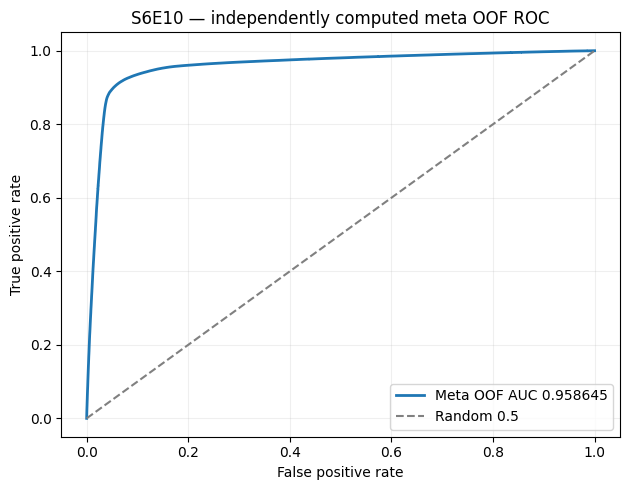

Key caveat: CV and public LB are different measures and may disagree.


In [8]:
fpr,tpr,_=roc_curve(y,meta_oof)
plt.figure(figsize=(6.4,5))
plt.plot(fpr,tpr,lw=2,label=f'Meta OOF AUC {meta_auc:.6f}')
plt.plot([0,1],[0,1],'--',color='gray',label='Random 0.5')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('S6E10 — independently computed meta OOF ROC')
plt.legend(loc='lower right');plt.grid(alpha=.2);plt.tight_layout();plt.show()
print('Key caveat: CV and public LB are different measures and may disagree.')